In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndi

from skimage import io, color, img_as_float
from pathlib import Path

print("환경 설정 완료")
print("현재 작업 경로:", Path.cwd())

환경 설정 완료
현재 작업 경로: c:\Users\user\OneDrive\바탕 화면\2026\2학기\의영처\chap5-1.hands-on.2026


1. Load the image file ‘roundImage.png’. Verify the data type of the loaded image array and convert it to 
a floating-point format if it is not already. 

In [2]:
import numpy as np
from skimage import io, img_as_float

# 이미지 불러오기
img = io.imread("roundImage.png")

# 불러온 영상 정보 확인
print("변환 전 자료형:", img.dtype)
print("영상 크기:", img.shape)

# 실수형이 아닐 경우 floating-point 형식으로 변환
if not np.issubdtype(img.dtype, np.floating):
    img = img_as_float(img)

print("변환 후 자료형:", img.dtype)
print("변환 후 픽셀 범위:", img.min(), "~", img.max())

변환 전 자료형: uint8
영상 크기: (257, 257)
변환 후 자료형: float64
변환 후 픽셀 범위: 0.0 ~ 1.0


2. Low-pass Filtering 

a) Create a 15x15 averaging filter mask and apply it to the input image. 

In [3]:
import scipy.ndimage as ndi

# 15×15 averaging filter mask 생성
avg_filter = np.ones((15, 15), dtype=float) / (15 * 15)

# 입력 영상에 평균 필터 적용
filtered_img = ndi.convolve(
    img,
    avg_filter,
    mode="reflect"
)

print("필터 크기:", avg_filter.shape)
print("필터 계수의 합:", avg_filter.sum())
print("결과 영상 크기:", filtered_img.shape)

필터 크기: (15, 15)
필터 계수의 합: 1.0
결과 영상 크기: (257, 257)


b) Display both the original and filtered images side by side. 

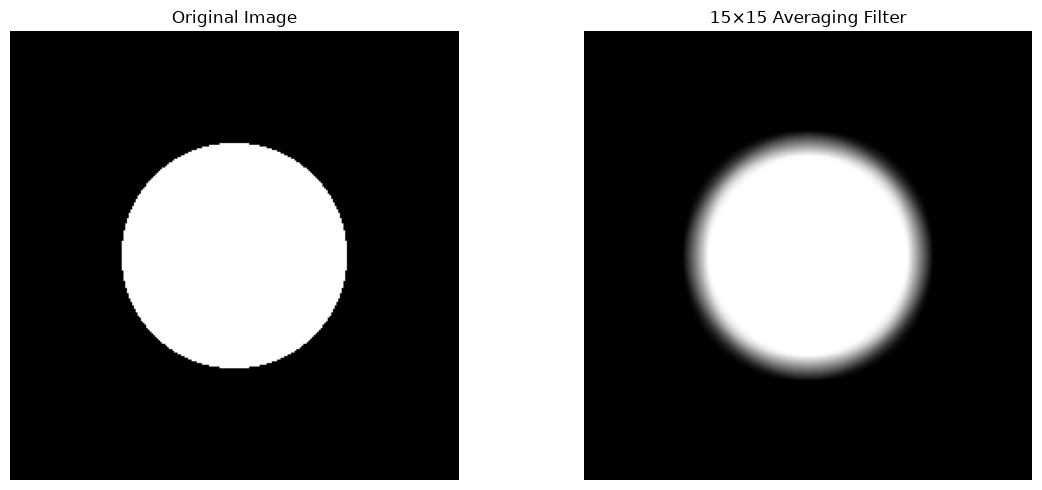

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# 원본 영상
plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

# 평균 필터 적용 영상
plt.subplot(1, 2, 2)
plt.imshow(filtered_img, cmap="gray")
plt.title("15×15 Averaging Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

c) Plot the intensity profiles along the central row of both images as illustrated below. 

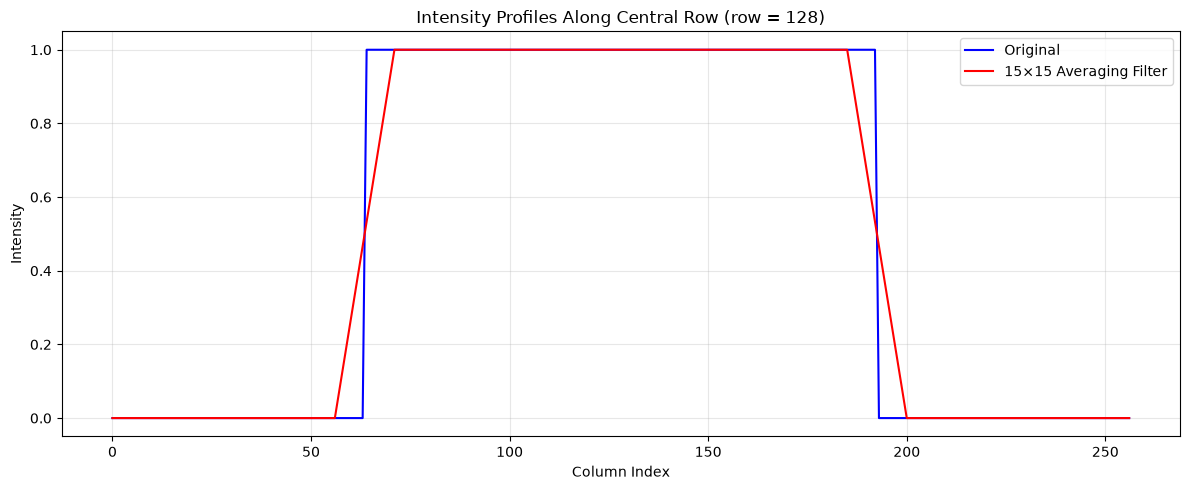

In [5]:
# 영상의 중앙 행 번호
center_row = img.shape[0] // 2

# 중앙 행의 intensity profile 추출
original_profile = img[center_row, :]
filtered_profile = filtered_img[center_row, :]

# 두 profile 비교
plt.figure(figsize=(12, 5))

plt.plot(
    original_profile,
    label="Original",
    color="blue"
)

plt.plot(
    filtered_profile,
    label="15×15 Averaging Filter",
    color="red"
)

plt.title(f"Intensity Profiles Along Central Row (row = {center_row})")
plt.xlabel("Column Index")
plt.ylabel("Intensity")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

d) Describe the differences observed between the original and filtered images. 

15×15 averaging low-pass filter (LPF)를 적용한 결과, 원본 영상의 sharp edge가 완만해지면서 blurring이 발생하였다. 이는 각 출력 화소의 gray value를 15×15 filter mask 내부 화소들의 평균으로 계산하기 때문에, 화소 사이의 급격한 gray-value 변화를 나타내는 high-frequency components가 attenuate되기 때문이다.
중앙 행의 intensity profile에서도 원본은 원의 경계에서 intensity가 0에서 1로 급격하게 변하지만, filtered image에서는 여러 화소에 걸쳐 점진적으로 변한다. 반면 원 내부와 배경처럼 gray value가 일정한 low-frequency regions은 각각 1과 0에 가깝게 유지된다. 따라서 averaging LPF는 high frequencies를 attenuate하여 영상을 smoothing하지만, 그 결과 sharp edges와 fine details가 흐려진다.

3. Filter Mask Creation and Visualization 

a) Generate a 3x3 Gaussian filter with a standard deviation of 0.5. 

3×3 Gaussian Filter
[[0.01134 0.08382 0.01134]
 [0.08382 0.61935 0.08382]
 [0.01134 0.08382 0.01134]]
Sum: 1.0


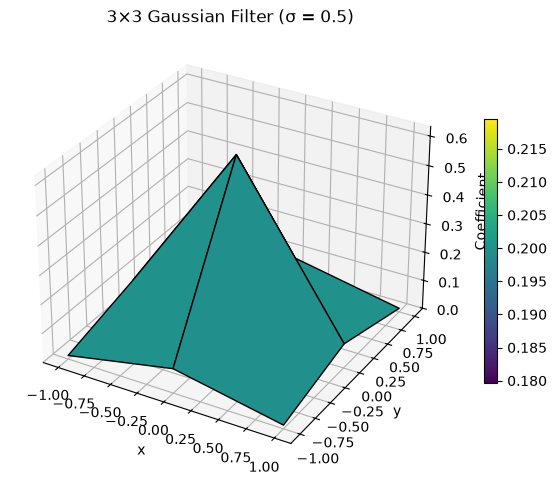

In [6]:
from mpl_toolkits.mplot3d import Axes3D

# 좌표 생성
x = np.arange(-1, 2)
y = np.arange(-1, 2)
xx, yy = np.meshgrid(x, y)

sigma = 0.5

# Gaussian filter 생성
gaussian_filter = np.exp(
    -(xx**2 + yy**2) / (2 * sigma**2)
)

# 필터 계수의 합이 1이 되도록 정규화
gaussian_filter /= gaussian_filter.sum()

print("3×3 Gaussian Filter")
print(np.round(gaussian_filter, 5))
print("Sum:", gaussian_filter.sum())

# 3D surface plot
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    xx,
    yy,
    gaussian_filter,
    cmap="viridis",
    edgecolor="black"
)

ax.set_title("3×3 Gaussian Filter (σ = 0.5)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("Coefficient")

fig.colorbar(surface, ax=ax, shrink=0.6)
plt.tight_layout()
plt.show()

b) Generate a 3x3 Laplacian filter with a center value of 4.

3×3 Laplacian Filter
[[ 0. -1.  0.]
 [-1.  4. -1.]
 [ 0. -1.  0.]]
Sum: 0.0


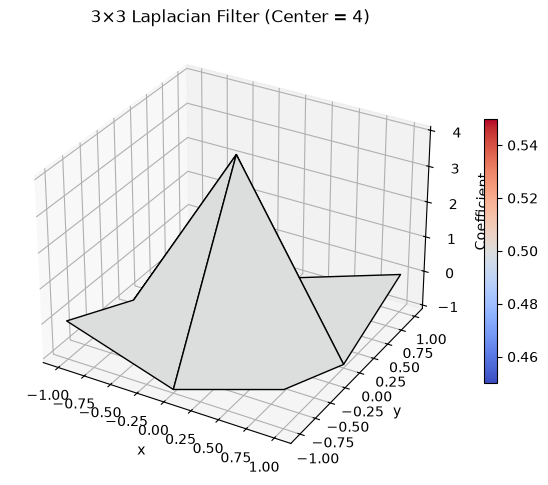

In [7]:
# Laplacian filter 생성
laplacian_filter = np.array([
    [ 0, -1,  0],
    [-1,  4, -1],
    [ 0, -1,  0]
], dtype=float)

print("3×3 Laplacian Filter")
print(laplacian_filter)
print("Sum:", laplacian_filter.sum())

# 좌표 생성
x = np.arange(-1, 2)
y = np.arange(-1, 2)
xx, yy = np.meshgrid(x, y)

# 3D surface plot
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    xx,
    yy,
    laplacian_filter,
    cmap="coolwarm",
    edgecolor="black"
)

ax.set_title("3×3 Laplacian Filter (Center = 4)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("Coefficient")

fig.colorbar(surface, ax=ax, shrink=0.6)
plt.tight_layout()
plt.show()


c) Generate a 3x3 Prewitt filter for detecting vertical edges. 

3×3 Prewitt Filter for Vertical Edges
[[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]
Sum: 0.0


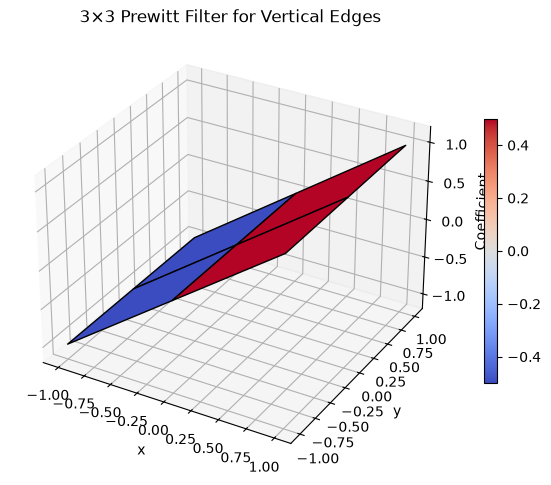

In [8]:
# 수직 에지 검출용 3×3 Prewitt filter
prewitt_filter = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=float)

print("3×3 Prewitt Filter for Vertical Edges")
print(prewitt_filter)
print("Sum:", prewitt_filter.sum())

# 3D surface plot용 좌표
x = np.arange(-1, 2)
y = np.arange(-1, 2)
xx, yy = np.meshgrid(x, y)

# 3D surface plot
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    xx,
    yy,
    prewitt_filter,
    cmap="coolwarm",
    edgecolor="black"
)

ax.set_title("3×3 Prewitt Filter for Vertical Edges")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("Coefficient")
ax.set_zlim(-1.2, 1.2)

fig.colorbar(surface, ax=ax, shrink=0.6)
plt.tight_layout()
plt.show()

3×3 Sobel Filter for Vertical Edges
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Sum: 0.0


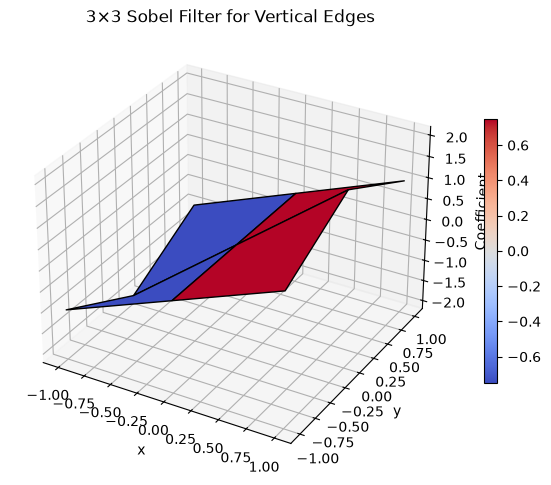

In [9]:
# 수직 에지 검출용 3×3 Sobel filter
sobel_filter = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

print("3×3 Sobel Filter for Vertical Edges")
print(sobel_filter)
print("Sum:", sobel_filter.sum())

# 3D surface plot용 좌표
x = np.arange(-1, 2)
y = np.arange(-1, 2)
xx, yy = np.meshgrid(x, y)

# 3D surface plot
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")

surface = ax.plot_surface(
    xx,
    yy,
    sobel_filter,
    cmap="coolwarm",
    edgecolor="black"
)

ax.set_title("3×3 Sobel Filter for Vertical Edges")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("Coefficient")
ax.set_zlim(-2.2, 2.2)

fig.colorbar(surface, ax=ax, shrink=0.6)
plt.tight_layout()
plt.show()

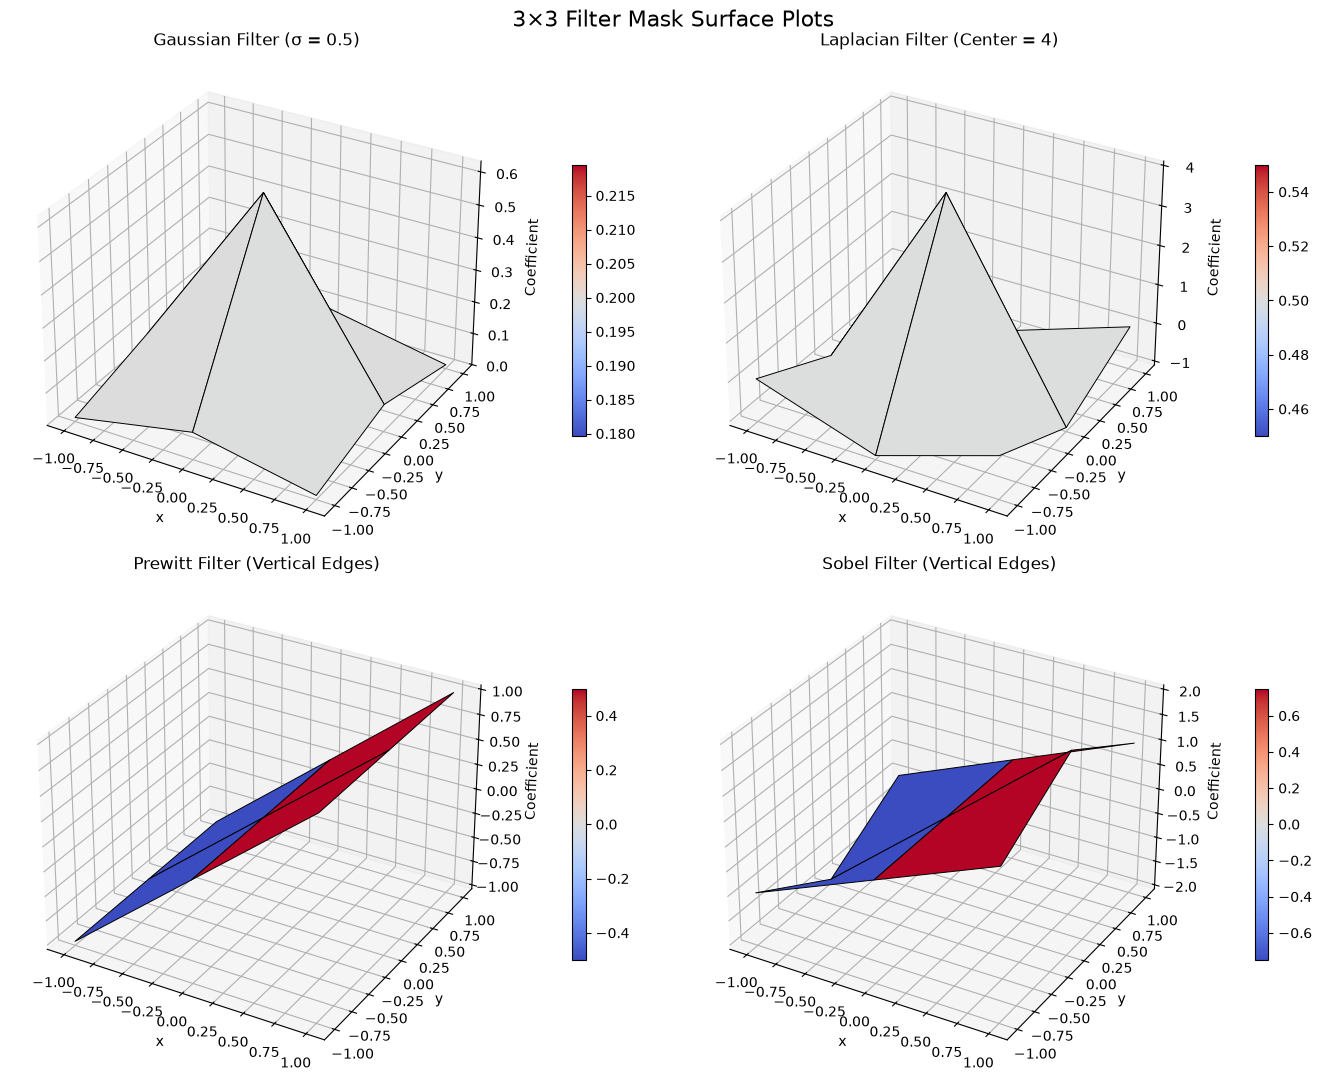

In [10]:
# 네 필터와 제목을 리스트로 정리
filters = [
    gaussian_filter,
    laplacian_filter,
    prewitt_filter,
    sobel_filter
]

titles = [
    "Gaussian Filter (σ = 0.5)",
    "Laplacian Filter (Center = 4)",
    "Prewitt Filter (Vertical Edges)",
    "Sobel Filter (Vertical Edges)"
]

# 3D surface plot용 좌표
x = np.arange(-1, 2)
y = np.arange(-1, 2)
xx, yy = np.meshgrid(x, y)

# 2×2 subplot 생성
fig = plt.figure(figsize=(14, 11))

for i, (filter_mask, title) in enumerate(zip(filters, titles), start=1):

    ax = fig.add_subplot(2, 2, i, projection="3d")

    surface = ax.plot_surface(
        xx,
        yy,
        filter_mask,
        cmap="coolwarm",
        edgecolor="black",
        linewidth=0.7
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("Coefficient")

    fig.colorbar(
        surface,
        ax=ax,
        shrink=0.55,
        pad=0.1
    )

plt.suptitle(
    "3×3 Filter Mask Surface Plots",
    fontsize=16,
    y=0.98
)

plt.tight_layout()
plt.show()

4. Directional Edge Detection Filters 

Sobel and Prewitt are basic high-pass filters with directional sensitivity. 

a) Apply the Sobel and Prewitt filters from step 3 to the input image. Show the filtered images and 
plot the horizontal center intensity profiles of the original image and both filtered outputs. Plot the 
vertical center profiles in a separate figure. 

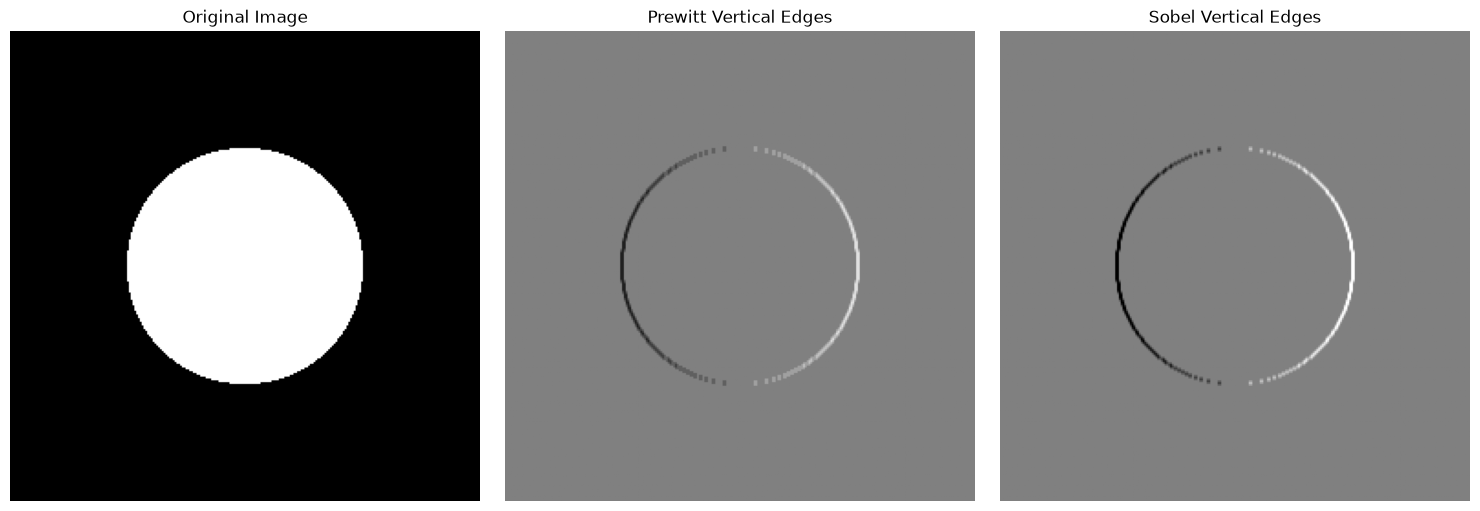

In [11]:
# 수직 에지 검출용 Prewitt와 Sobel 필터 적용
prewitt_vertical = ndi.convolve(
    img,
    prewitt_filter,
    mode="reflect"
)

sobel_vertical = ndi.convolve(
    img,
    sobel_filter,
    mode="reflect"
)

# --------------------------------------------------
# 1. 원본 및 필터링 영상 표시
# --------------------------------------------------

# 두 필터 결과에서 가장 큰 절댓값 계산
max_response = max(
    np.max(np.abs(prewitt_vertical)),
    np.max(np.abs(sobel_vertical))
)

plt.figure(figsize=(15, 5))

# 원본 영상
plt.subplot(1, 3, 1)
plt.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Original Image")
plt.axis("off")

# Prewitt 필터의 signed response
plt.subplot(1, 3, 2)
plt.imshow(
    prewitt_vertical,
    cmap="gray",
    vmin=-max_response,
    vmax=max_response
)
plt.title("Prewitt Vertical Edges")
plt.axis("off")

# Sobel 필터의 signed response
plt.subplot(1, 3, 3)
plt.imshow(
    sobel_vertical,
    cmap="gray",
    vmin=-max_response,
    vmax=max_response
)
plt.title("Sobel Vertical Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

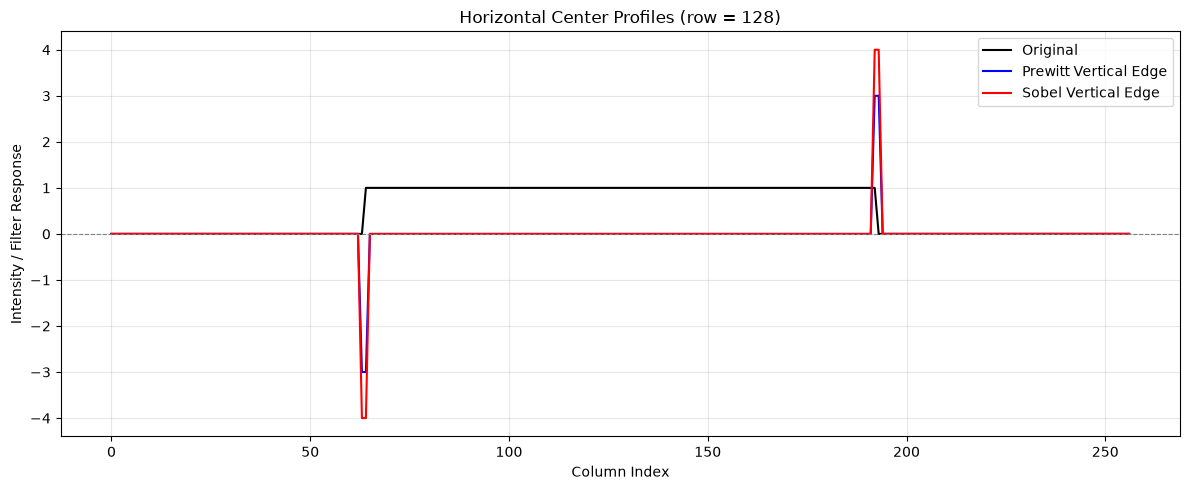

In [12]:
center_row = img.shape[0] // 2

plt.figure(figsize=(12, 5))

plt.plot(
    img[center_row, :],
    label="Original",
    color="black"
)

plt.plot(
    prewitt_vertical[center_row, :],
    label="Prewitt Vertical Edge",
    color="blue"
)

plt.plot(
    sobel_vertical[center_row, :],
    label="Sobel Vertical Edge",
    color="red"
)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title(
    f"Horizontal Center Profiles (row = {center_row})"
)
plt.xlabel("Column Index")
plt.ylabel("Intensity / Filter Response")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

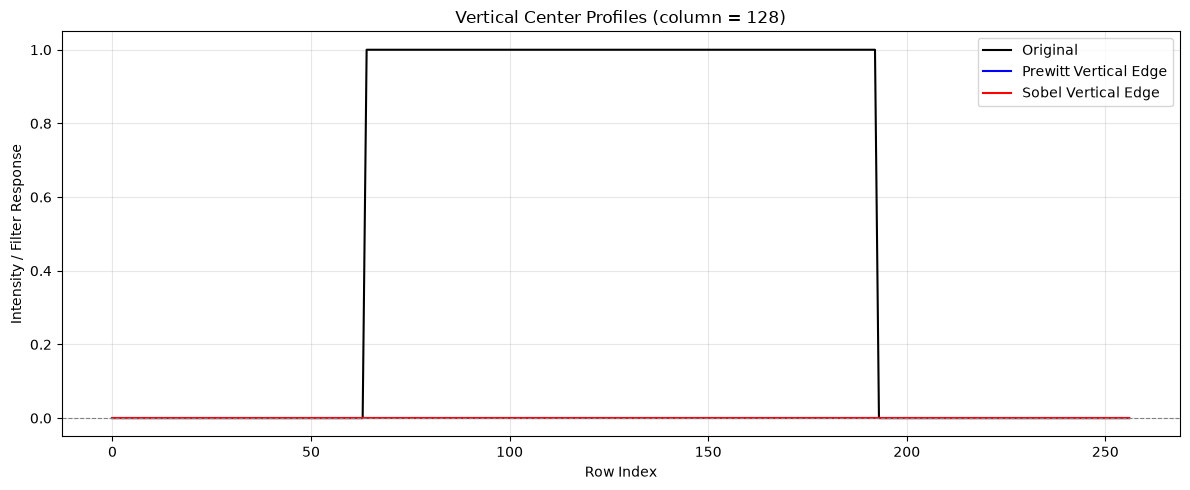

In [13]:
center_col = img.shape[1] // 2

plt.figure(figsize=(12, 5))

plt.plot(
    img[:, center_col],
    label="Original",
    color="black"
)

plt.plot(
    prewitt_vertical[:, center_col],
    label="Prewitt Vertical Edge",
    color="blue"
)

plt.plot(
    sobel_vertical[:, center_col],
    label="Sobel Vertical Edge",
    color="red"
)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)

plt.title(
    f"Vertical Center Profiles (column = {center_col})"
)
plt.xlabel("Row Index")
plt.ylabel("Intensity / Filter Response")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

b) Repeat (a) using the transposed Sobel and Prewitt filters to detect horizontal edges instead. 

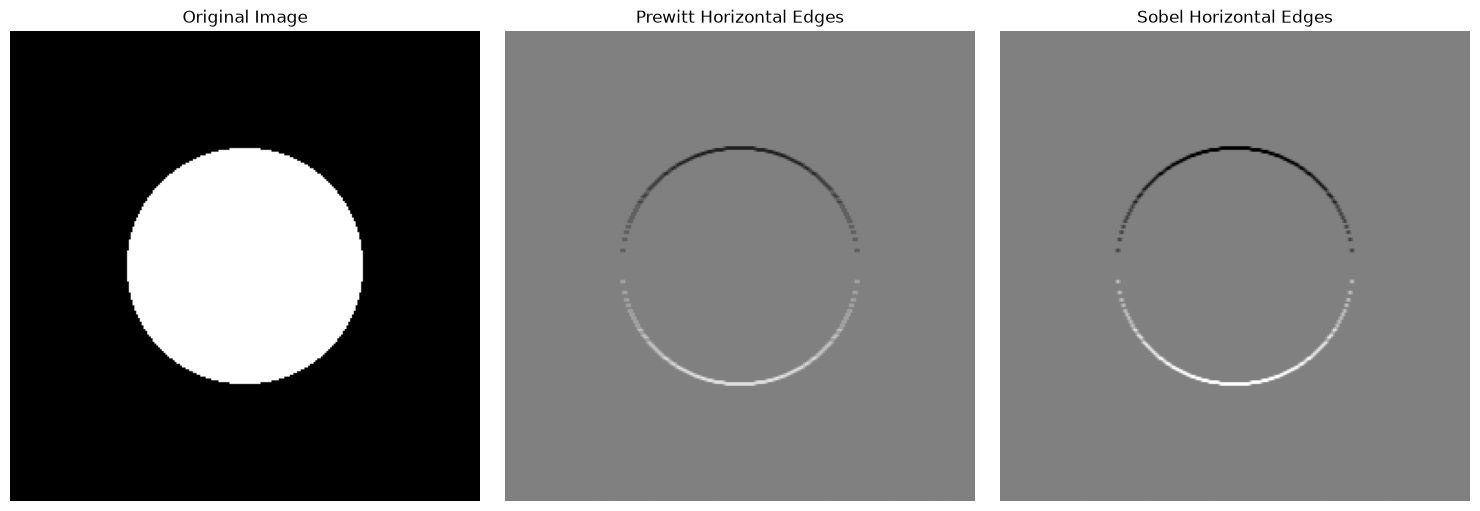

In [14]:
# 수직 에지 필터를 전치하여 수평 에지 필터 생성
prewitt_filter_T = prewitt_filter.T
sobel_filter_T = sobel_filter.T

# 수평 에지 검출
prewitt_horizontal = ndi.convolve(
    img,
    prewitt_filter_T,
    mode="reflect"
)

sobel_horizontal = ndi.convolve(
    img,
    sobel_filter_T,
    mode="reflect"
)

# 두 결과에 동일한 표시 범위 적용
max_response = max(
    np.max(np.abs(prewitt_horizontal)),
    np.max(np.abs(sobel_horizontal))
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    img,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Original Image")
plt.axis("off")

# 절댓값을 사용하지 않고 signed response 표시
plt.subplot(1, 3, 2)
plt.imshow(
    prewitt_horizontal,
    cmap="gray",
    vmin=-max_response,
    vmax=max_response
)
plt.title("Prewitt Horizontal Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    sobel_horizontal,
    cmap="gray",
    vmin=-max_response,
    vmax=max_response
)
plt.title("Sobel Horizontal Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

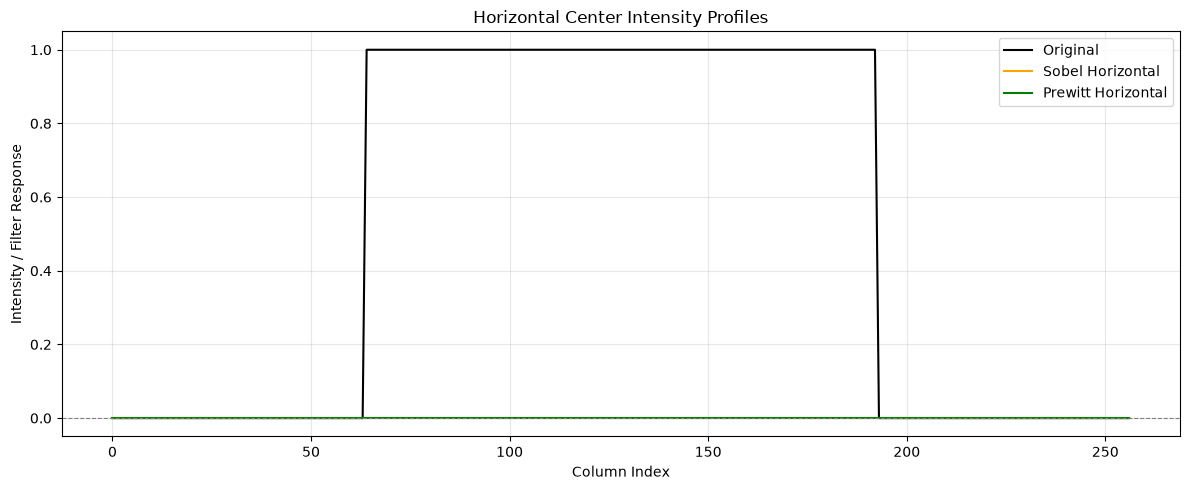

In [15]:
center_row = img.shape[0] // 2

plt.figure(figsize=(12, 5))

plt.plot(
    img[center_row, :],
    label="Original",
    color="black"
)

plt.plot(
    sobel_horizontal[center_row, :],
    label="Sobel Horizontal",
    color="orange"
)

plt.plot(
    prewitt_horizontal[center_row, :],
    label="Prewitt Horizontal",
    color="green"
)

plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=0.8
)

plt.title("Horizontal Center Intensity Profiles")
plt.xlabel("Column Index")
plt.ylabel("Intensity / Filter Response")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

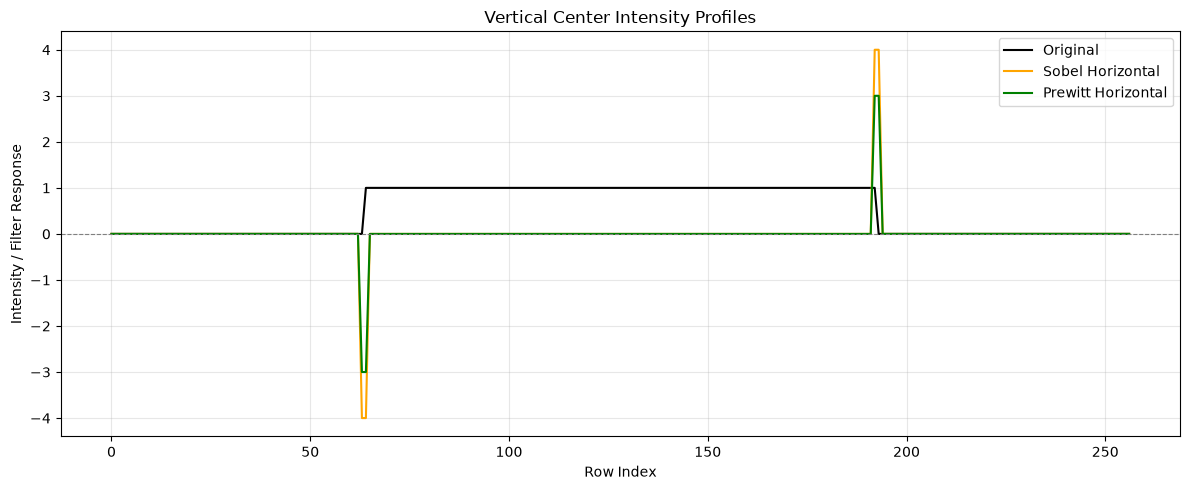

In [16]:
center_col = img.shape[1] // 2

plt.figure(figsize=(12, 5))

plt.plot(
    img[:, center_col],
    label="Original",
    color="black"
)

plt.plot(
    sobel_horizontal[:, center_col],
    label="Sobel Horizontal",
    color="orange"
)

plt.plot(
    prewitt_horizontal[:, center_col],
    label="Prewitt Horizontal",
    color="green"
)

plt.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=0.8
)

plt.title("Vertical Center Intensity Profiles")
plt.xlabel("Row Index")
plt.ylabel("Intensity / Filter Response")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


c) Combine the outputs from (a) and (b) to extract omni-directional edges. Display the resulting 
images and their intensity profiles. 

In [17]:
# Prewitt 전방향 에지 강도
prewitt_omni = np.sqrt(
    prewitt_vertical**2
    + prewitt_horizontal**2
)

# Sobel 전방향 에지 강도
sobel_omni = np.sqrt(
    sobel_vertical**2
    + sobel_horizontal**2
)

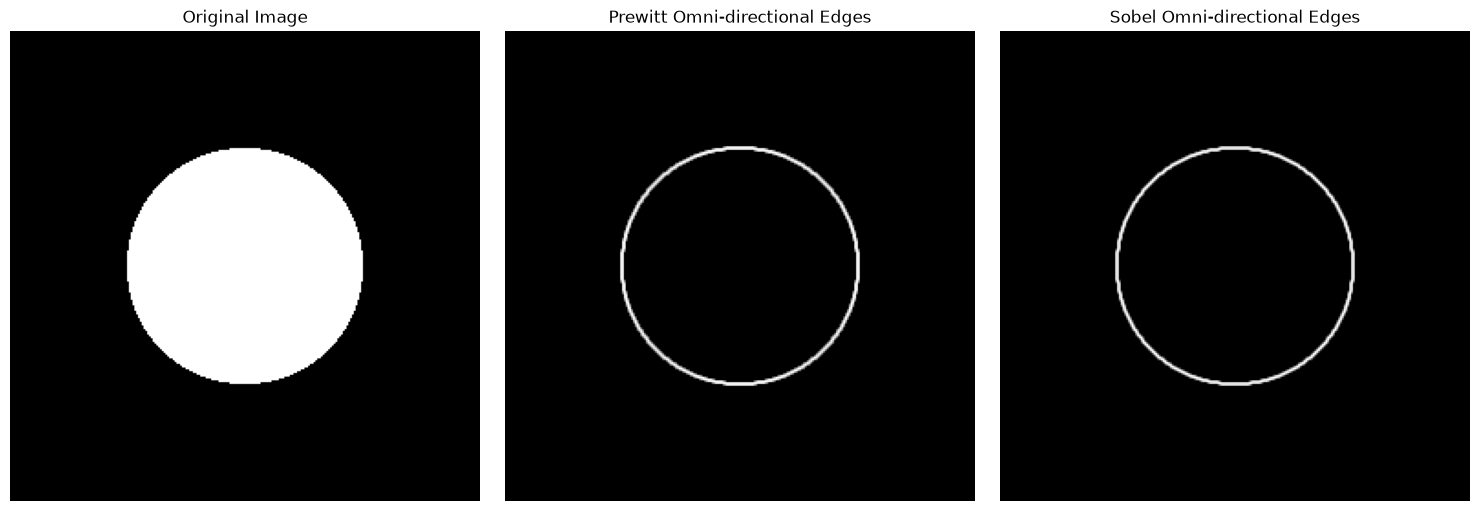

In [18]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(prewitt_omni, cmap="gray")
plt.title("Prewitt Omni-directional Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sobel_omni, cmap="gray")
plt.title("Sobel Omni-directional Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

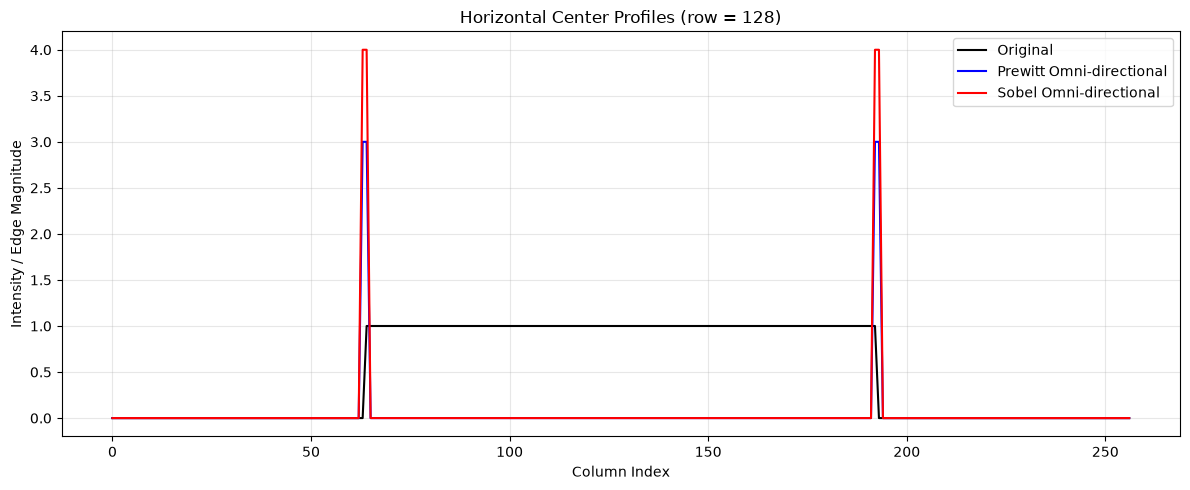

In [19]:
center_row = img.shape[0] // 2

plt.figure(figsize=(12, 5))

plt.plot(
    img[center_row, :],
    label="Original",
    color="black"
)

plt.plot(
    prewitt_omni[center_row, :],
    label="Prewitt Omni-directional",
    color="blue"
)

plt.plot(
    sobel_omni[center_row, :],
    label="Sobel Omni-directional",
    color="red"
)

plt.title(
    f"Horizontal Center Profiles (row = {center_row})"
)
plt.xlabel("Column Index")
plt.ylabel("Intensity / Edge Magnitude")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

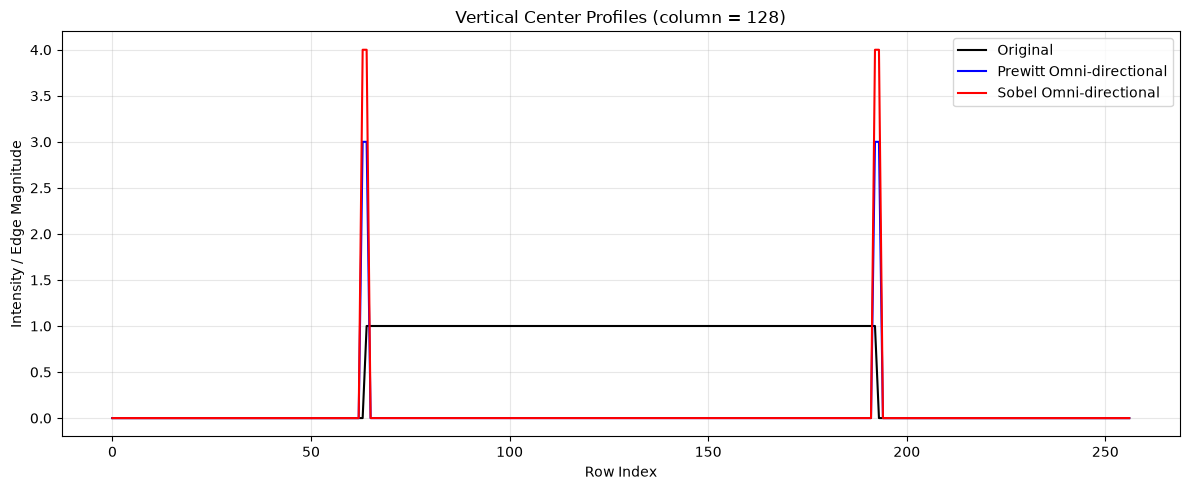

In [20]:
center_col = img.shape[1] // 2

plt.figure(figsize=(12, 5))

plt.plot(
    img[:, center_col],
    label="Original",
    color="black"
)

plt.plot(
    prewitt_omni[:, center_col],
    label="Prewitt Omni-directional",
    color="blue"
)

plt.plot(
    sobel_omni[:, center_col],
    label="Sobel Omni-directional",
    color="red"
)

plt.title(
    f"Vertical Center Profiles (column = {center_col})"
)
plt.xlabel("Row Index")
plt.ylabel("Intensity / Edge Magnitude")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

d) Compute and display the difference image by taking the absolute difference between the two 
output images from (c).

Difference image shape: (257, 257)
Minimum difference: 0.0
Maximum difference: 1.4142135623730945


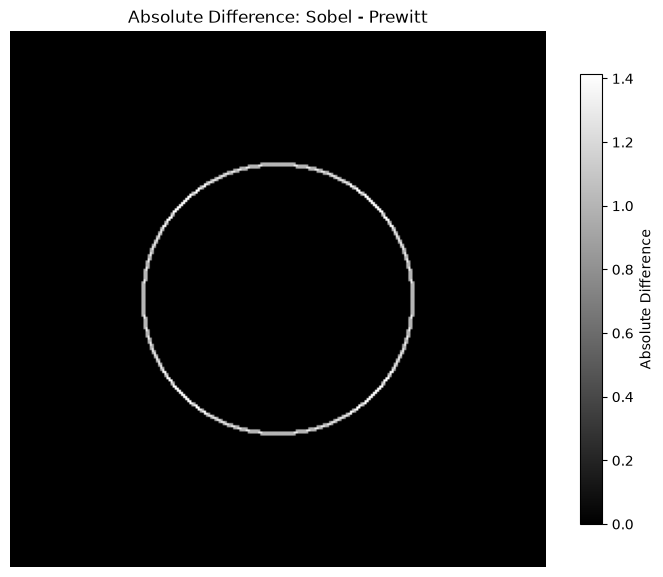

In [21]:
# Sobel과 Prewitt 전방향 에지 결과의 절대 차이
difference_image = np.abs(
    sobel_omni - prewitt_omni
)

print("Difference image shape:", difference_image.shape)
print("Minimum difference:", difference_image.min())
print("Maximum difference:", difference_image.max())

# 차영상 표시
plt.figure(figsize=(7, 6))

plt.imshow(difference_image, cmap="gray")
plt.title(
    "Absolute Difference: Sobel - Prewitt"
)
plt.axis("off")
plt.colorbar(
    label="Absolute Difference",
    shrink=0.8
)

plt.tight_layout()
plt.show()

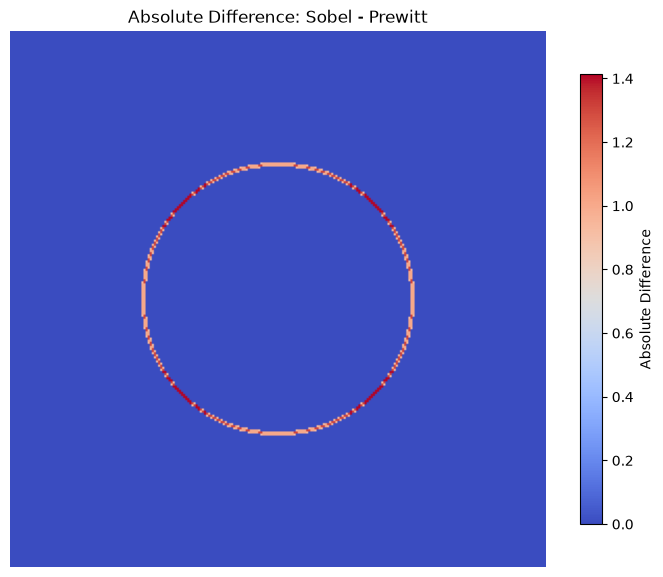

In [22]:
plt.figure(figsize=(7, 6))

plt.imshow(
    difference_image,
    cmap="coolwarm"
)

plt.title("Absolute Difference: Sobel - Prewitt")
plt.axis("off")
plt.colorbar(
    label="Absolute Difference",
    shrink=0.8
)

plt.tight_layout()
plt.show()

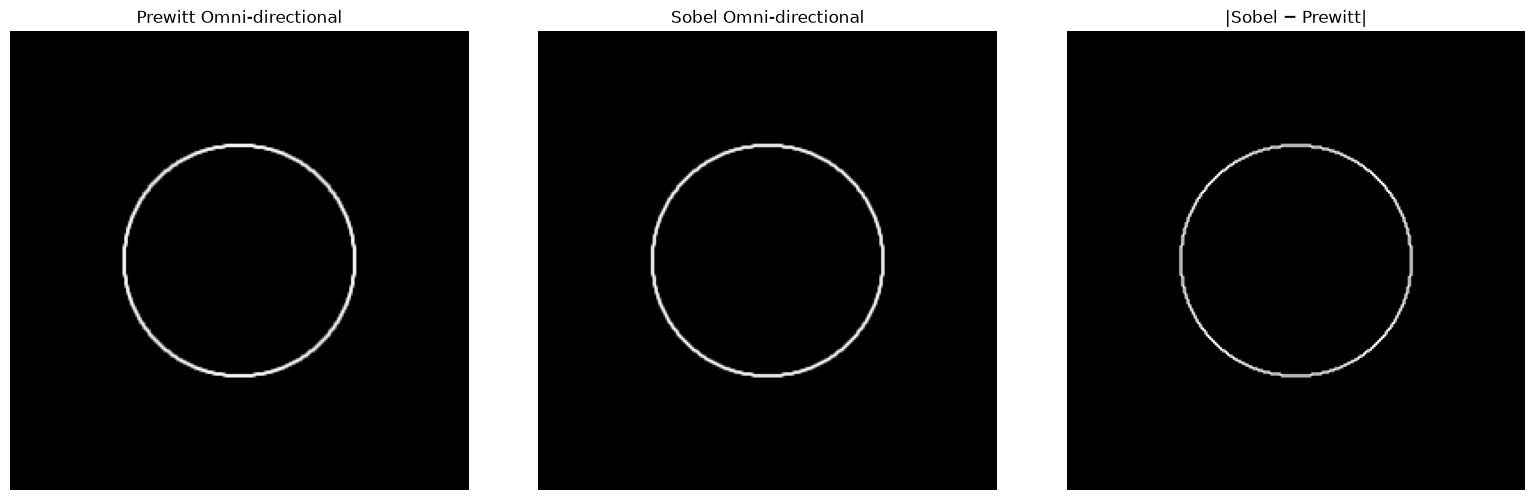

In [23]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(prewitt_omni, cmap="gray")
plt.title("Prewitt Omni-directional")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sobel_omni, cmap="gray")
plt.title("Sobel Omni-directional")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(difference_image, cmap="gray")
plt.title("|Sobel − Prewitt|")
plt.axis("off")

plt.tight_layout()
plt.show()

5. High-pass Filter Application 

a) Load the image file ‘chest.png’. 

In [24]:
# chest.png 불러오기
chest_img = io.imread("chest.png")

# 원본 영상 정보 확인
print("변환 전 자료형:", chest_img.dtype)
print("영상 크기:", chest_img.shape)
print(
    "변환 전 픽셀 범위:",
    chest_img.min(),
    "~",
    chest_img.max()
)

# 실수형이 아니면 floating-point 형식으로 변환
if not np.issubdtype(chest_img.dtype, np.floating):
    chest_img = img_as_float(chest_img)

print("변환 후 자료형:", chest_img.dtype)
print(
    "변환 후 픽셀 범위:",
    chest_img.min(),
    "~",
    chest_img.max()
)

변환 전 자료형: uint8
영상 크기: (252, 302)
변환 전 픽셀 범위: 0 ~ 241
변환 후 자료형: float64
변환 후 픽셀 범위: 0.0 ~ 0.9450980392156862


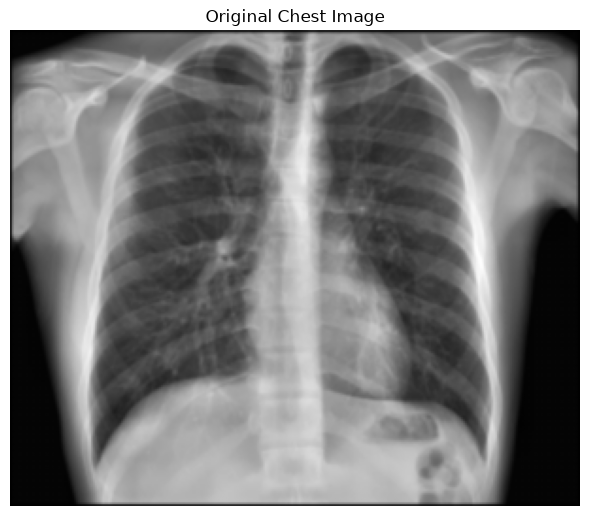

In [25]:
plt.figure(figsize=(6, 6))

plt.imshow(chest_img, cmap="gray")
plt.title("Original Chest Image")
plt.axis("off")

plt.tight_layout()
plt.show()

b) Apply the Laplacian filter created in step 3.b to the chest image. 

In [26]:
# Step 3.b에서 만든 Laplacian filter 확인
print(laplacian_filter)

# chest 영상에 Laplacian filter 적용
chest_laplacian = ndi.convolve(
    chest_img,
    laplacian_filter,
    mode="reflect"
)

print("Laplacian 결과 자료형:", chest_laplacian.dtype)
print(
    "Laplacian 결과 범위:",
    chest_laplacian.min(),
    "~",
    chest_laplacian.max()
)

[[ 0. -1.  0.]
 [-1.  4. -1.]
 [ 0. -1.  0.]]
Laplacian 결과 자료형: float64
Laplacian 결과 범위: -0.43137254901960786 ~ 0.32156862745098025


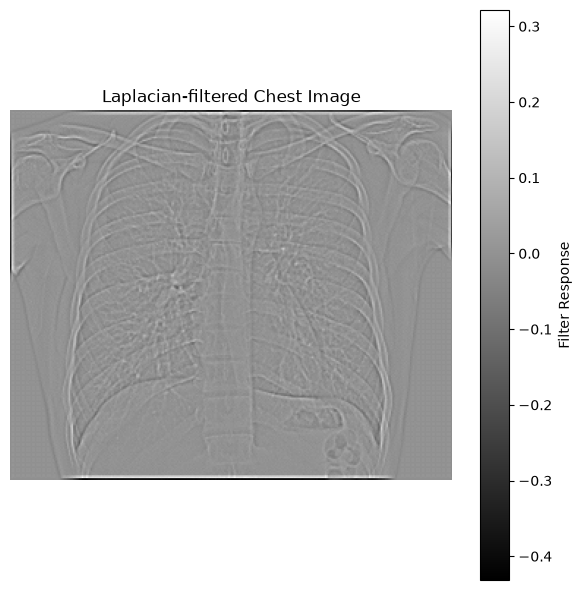

In [27]:
plt.figure(figsize=(6, 6))

# 양수와 음수 응답을 구분하기 위해 gray와 자동 범위를 사용
plt.imshow(chest_laplacian, cmap="gray")
plt.title("Laplacian-filtered Chest Image")
plt.axis("off")
plt.colorbar(label="Filter Response")

plt.tight_layout()
plt.show()

c) Use the Laplacian filter output to enhance the sharpness of the original chest image. 

In [28]:
# Laplacian 결과를 원본에 더하여 sharpening
chest_sharpened = chest_img + chest_laplacian

# 표시 가능한 범위 [0, 1]로 제한
chest_sharpened = np.clip(
    chest_sharpened,
    0,
    1
)

print(
    "Sharpened image range:",
    chest_sharpened.min(),
    "~",
    chest_sharpened.max()
)

Sharpened image range: 0.0 ~ 1.0


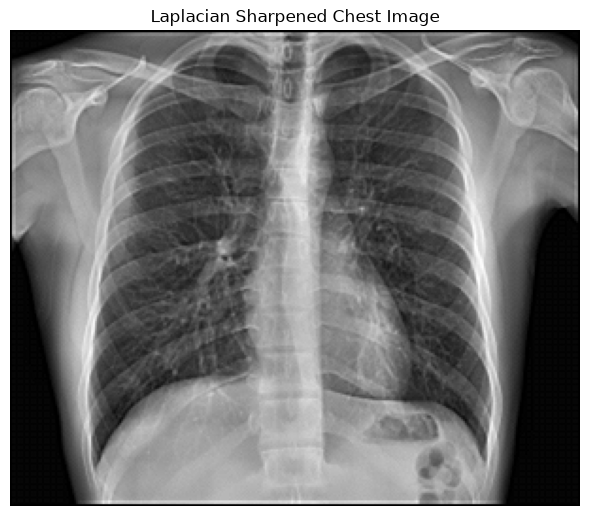

In [29]:
plt.figure(figsize=(6, 6))

plt.imshow(chest_sharpened, cmap="gray")
plt.title("Laplacian Sharpened Chest Image")
plt.axis("off")

plt.tight_layout()
plt.show()

d) Display the original, the Laplacian-filtered, and the sharpened images side by side. 

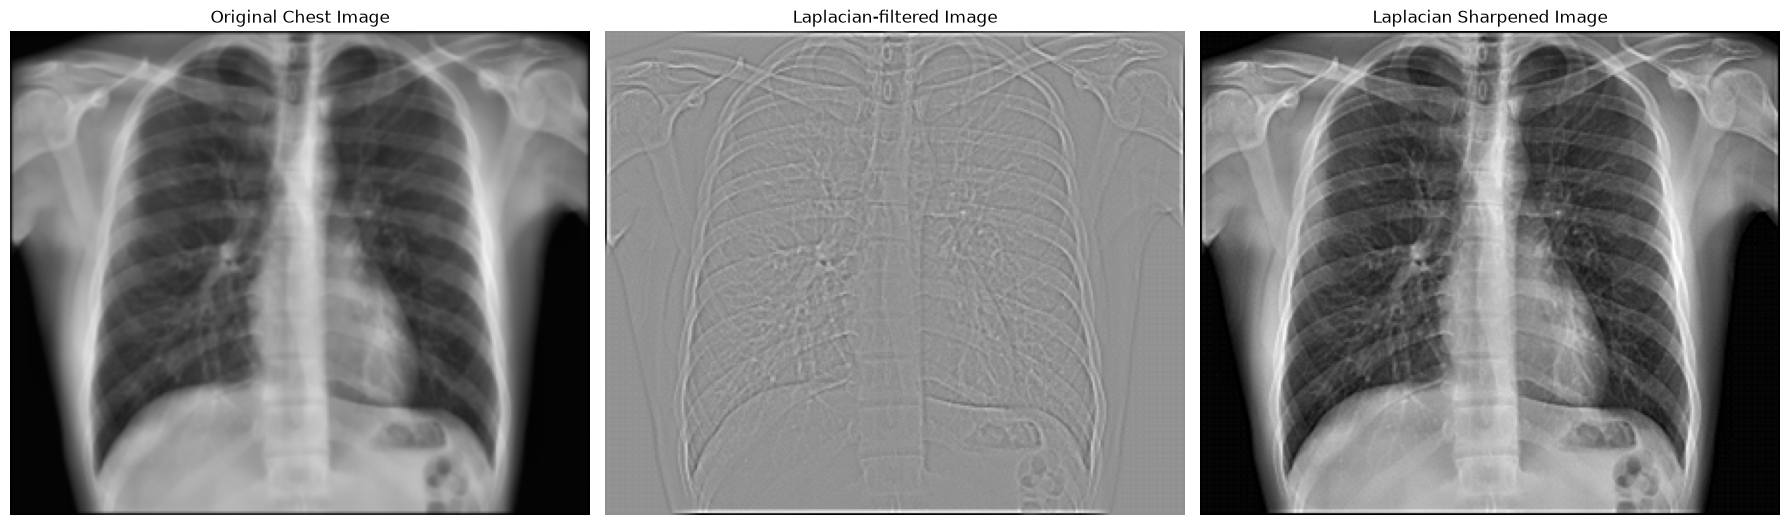

In [30]:
plt.figure(figsize=(18, 6))

# 원본 영상
plt.subplot(1, 3, 1)
plt.imshow(
    chest_img,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Original Chest Image")
plt.axis("off")

# Laplacian 필터 출력
plt.subplot(1, 3, 2)
plt.imshow(
    chest_laplacian,
    cmap="gray"
)
plt.title("Laplacian-filtered Image")
plt.axis("off")

# Sharpened 영상
plt.subplot(1, 3, 3)
plt.imshow(
    chest_sharpened,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Laplacian Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()